
<div align="center">
  <a href="https://github.com/ESAOpenSR/">
    <img src="https://github.com/ESAOpenSR/opensr-model/blob/main/resources/images/opensr_logo.png?raw=true" width="250"/>
  </a>
</div>
<div align="center">
  <a href="https://github.com/ESAOpenSR/opensr-model">
    <img src="https://github.com/ESAOpenSR/opensr-model/blob/main/resources/images/model_repo_icon.png?raw=true" width="120"/>
  </a>

<br/>
<br/>

</div>

   


# LDSR-S2 Model

This is a code-walkthrough example. If you just want to check the results, have a look at the **No-Code Example**, which allows you to select your S2 input on a map: [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ESAOpenSR/opensr-model/blob/main/resources/notebooks/%28public%29_LDSR_S2_No_Code.ipynb)  

This interactive Notebook shows the super-resolution of Sentinel-2 BOA RGB-NIR data, based on the publication [Trustworthy Super-Resolution of Multispectral Sentinel-2 Imagery with Latent Diffusion](https://ieeexplore.ieee.org/abstract/document/10887321).

> ⚠️ **GPU required**: make sure to start this notebook in a GPU environment.


This Notebook features the following:
1.   Local install of the package, creating the model, downloading the newest weights.
2.   SR of a patch downloaded straight from S2
3.   Generation of uncertainty map of the example
4.   Plotting of the results



<img src="https://github.com/ESAOpenSR/opensr-model/blob/main/resources/images/ldsr-s2_schema.png?raw=true" width="750"/>

If you use this model in your work, please cite:


```
@ARTICLE{ldsrs2,
  author={Donike, Simon and Aybar, Cesar and Gómez-Chova, Luis and Kalaitzis, Freddie},
  journal={IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing},
  title={Trustworthy Super-Resolution of Multispectral Sentinel-2 Imagery With Latent Diffusion},
  year={2025},
  volume={18},
  number={},
  pages={6940-6952},
  doi={10.1109/JSTARS.2025.3542220}}
```





# 0. Install and Imports
Install opensr_model from pip and install all the dependencies.
> ⚠️ **Warning** This might take a moment due to the need to change cuda/torch versions  

In [ ]:
!pip install opensr-model
!pip install git+https://github.com/ESDS-Leipzig/cubo.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.6/53.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.5/849.5 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 32.5 MB/s eta 0:00:00
  Cloning https://github.com/ESDS-Leipzig/cubo.git to /tmp/pip-req-build-j7bz07e9
  Running command git clone --filter=blob:none --quiet https://github.com/ESDS-Leipzig/cubo.git /tmp/pip-req-build-j7bz07e9
  Resolved https://github.com/ESDS-Leipzig/cubo.git to commit 4abf1ae11b99871116ba939558a1ab0dd31e3a82
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.2/208.2 kB 12.8 MB/s eta 0:00:00
  Created wheel for cubo: filename=cubo-2024.8.0-py3-none-any.whl size=10158 sha256=e3a368fa50aca811ca3d279d830bc658933d6afc52bcb73068dc749f8859884b
  Stored in directory: /

In [ ]:
# Import Model Package
import opensr_model

# other inmports
import torch
from omegaconf import OmegaConf
from importlib.resources import files
from io import StringIO
import requests
from IPython.display import Image, display
import cubo
import numpy as np

# Set Device
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Instanciating the model
First, we load the config file from the GitHub repository. Alternatively, you can save it locally or modify your own.  
Then, we create the model and load the weights from HuggingFace and into the model.

In [ ]:
# get Config File
config_url = "https://github.com/ESAOpenSR/opensr-model/raw/refs/heads/main/opensr_model/configs/config_10m.yaml"
response = requests.get(config_url)
config = OmegaConf.load(StringIO(response.text))

In [ ]:
# -------------------------------------------------------------------------------------
# 0.0 Create Model
# Make sure you're running this Notebook in a GPU environment
model = opensr_model.SRLatentDiffusion(config, device=device) # create model
model.load_pretrained(config.ckpt_version) # download checkpint
assert model.training == False, "Model has to be in eval mode."

LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.
Loaded pretrained weights from:  opensr-ldsrs2_v1_0_0.ckpt


# 2. Get Data
Here, we get a S2 patch from the input coordinates via Cubo. Select your location by replacing the coordinates.

> To SR whole S2 scenes, check out the [opensr-utils](https://github.com/ESAOpenSR/opensr-utils) package, which automatizes patched inference for the `.SAFE` file format.



In [ ]:
def get_s2_scene(LATITUDE,LONGITUDE,START_DATE,END_DATE):
  # In the START_DATE & END_DATE range, there can be multiple images. This index is used to select one of them.
  IMAGE_INDEX = 0

  # Create a Sentinel-2 L2A data cube for a specific location and date range
  da = cubo.create(
      lat=LATITUDE, # set coor's
      lon=LONGITUDE,
      collection="sentinel-2-l2a", # select product
      bands=["B04", "B03", "B02", "B08"], # Define RGB-NIR
      start_date=START_DATE, # set dates
      end_date=END_DATE,
      edge_size=128, # get only patch size which model expects
      resolution=10) # get native 10m resolution

  # preprocess image: normalize and unsqueeze
  original_s2_numpy = (da[IMAGE_INDEX].compute().to_numpy()).astype("float32")
  low_resolution = torch.from_numpy(original_s2_numpy).float().to(device)
  low_resolution = low_resolution / 10_000 # bring to 0..1
  low_resolution = low_resolution.unsqueeze(0) # bring to Bx4x128x128
  low_resolution = torch.nan_to_num(low_resolution,0.0) # get rif of invalid pixels
  return(low_resolution)

In [ ]:
# Define Coordinates and Time
LATITUDE = 43.80098464237228
LONGITUDE = -0.028923459950529546
START_DATE = "2024-04-01" # Set date (be mindful of cloud cover)
END_DATE = "2024-05-30"

# Get image - Shape needs to be Bx4x128x128
lr = get_s2_scene(LATITUDE,LONGITUDE,START_DATE,END_DATE)

# 3. Running the model
Now, we run the model on an example and plot the results.

In [ ]:
# Run Super-Resolution
sr = model.forward(lr, sampling_steps=200) # Tip: 100 steps for faster performance

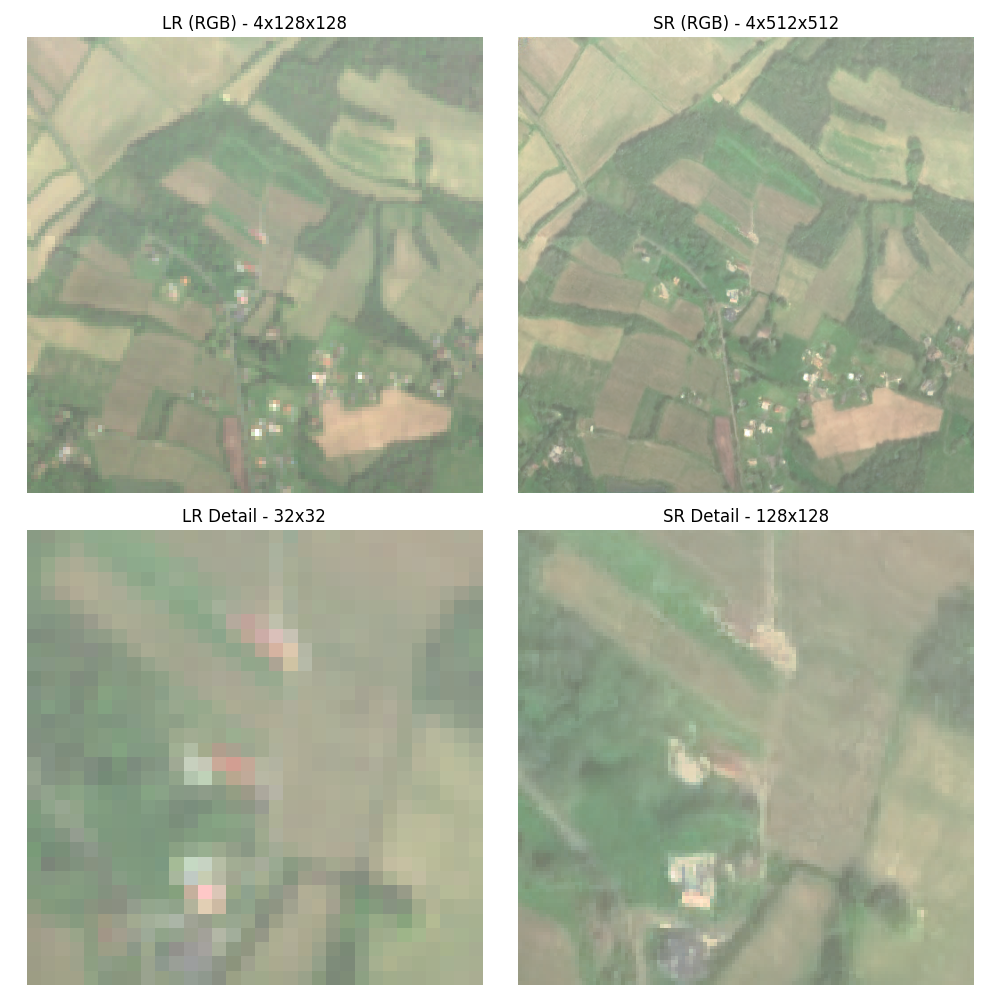

In [ ]:
# Inspect Result
from opensr_model.utils import plot_example
plot_example(lr,sr,out_file="example.png")
display(Image(filename="example.png"))

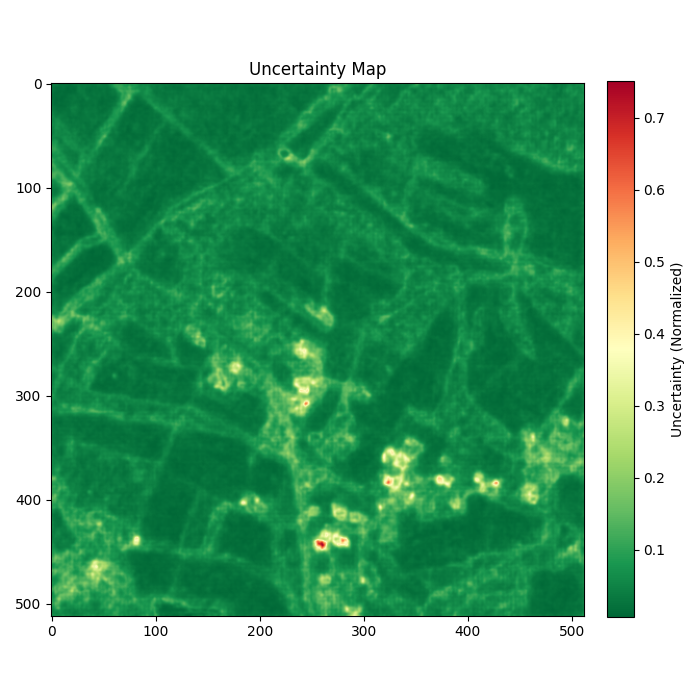

In [ ]:
# -------------------------------------------------------------------------------------
# Run Encertainty Map Generation
# Due to the many samples needed, this might take a moment.
uncertainty_map = model.uncertainty_map(lr,n_variations=20,sampling_steps=100)

# Inspect Plot Result
from opensr_model.utils import plot_uncertainty,plot_example
plot_uncertainty(uncertainty_map,out_file="uncertainty_map.png",normalize=True)
display(Image(filename="uncertainty_map.png"))